# 07 · Protección de datos y ética (R6)
**Proyecto semestral · Sala de crisis COVID-19 · Gestión de Datos IN1232C · 2026-2**

Requiere `03_dw_estrella`. Contenidos de la S7.

1. ¿Son **datos personales** los conteos de COVID-19 por territorio? (Ley 19.628 y Ley 21.719)
2. **Celdas pequeñas**: territorios con poca población y conteos de 1 a 4.
3. **Regla de supresión** (la misma que aplica el tablero) y el problema de la supresión complementaria.
4. **Condados de EE.UU.** con menos de 5.000 habitantes: cuánta información se pierde al suprimir.
5. **Advertencias de interpretación** para el Comité.

## 1 · ¿Son datos personales?

**Qué dice la ley**
- **Ley 19.628** (vigente): dato personal es cualquier información concerniente a personas naturales **identificadas o identificables**. Los **estados de salud** son **datos sensibles**. La ley distingue el **dato estadístico**: el que, en su origen o por su tratamiento, **no puede asociarse a un titular** identificado o identificable.
- **Ley 21.719** (publicada en diciembre de 2024; modifica la 19.628 y entra en vigencia el 1-dic-2026): mantiene la idea central (*cualquier información vinculada o referida a una persona natural identificada o identificable*), trata los datos de **salud** como **sensibles**, crea la **Agencia de Protección de Datos Personales** y define la **anonimización** como un procedimiento **irreversible**: un dato anonimizado **deja de ser** un dato personal.

**Nuestro caso**
- Los reportes de JHU son **conteos agregados** (casos y fallecidos acumulados por país, región o condado y día). No traen nombre, RUT, edad ni sexo. En un territorio grande, un conteo no puede asociarse a nadie: es un **dato estadístico**, fuera del concepto de dato personal.
- **Pero pueden llegar a serlo.** La palabra clave es *identificable* (S7). Si un condado de 400 habitantes informa **1 fallecido** un día, ese número combinado con información pública (un obituario, la radio local, los vecinos) identifica a una persona y revela un **dato de salud** (dato sensible). Es el mismo ataque del laboratorio de la S7: no se necesita el nombre, basta con quedar **solo en su combinación** (territorio pequeño + fecha + conteo bajo).
- **Base de licitud del dato original:** el tratamiento lo hicieron las autoridades sanitarias por **interés público**. Nosotros solo **reutilizamos** datos ya agregados; nuestra obligación es **no reidentificar** y **no publicar** combinaciones que permitan hacerlo.

**Conclusión:** los datos agregados de JHU **no son datos personales en general**, pero las **celdas pequeñas** (pocos habitantes y conteos de 1 a 4) sí pueden permitir identificar a personas. Para ellas aplicamos un **control de divulgación** antes de publicar en el tablero.

## Setup

In [1]:
import os
import shutil
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)

from google.colab import drive
drive.mount('/content/drive')

PROYECTO = '/content/drive/MyDrive/proyecto-gestion-datos-2026'
shutil.copy(os.path.join(PROYECTO, 'data', 'dw', 'covid_dw.db'), '/content/covid_dw.db')
dw = sqlite3.connect('/content/covid_dw.db')

## 2 · Celdas pequeñas
**Celda** = un territorio en una semana (lunes a domingo). Es **pequeña** si el territorio tiene **menos de 100.000 habitantes** y el conteo semanal está **entre 1 y 4** (con 0 no se revela a nadie; con 5 o más, la persona se pierde en el grupo: es la idea de **k-anonimato con k = 5** de la S7).

In [2]:
UMBRAL_POBLACION = 100000
MINIMO, MAXIMO = 1, 4

semanal = pd.read_sql("""
    SELECT t.territorio_key, t.pais, t.region, t.condado, t.nivel, t.poblacion,
           DATE(d.fecha, '-6 days', 'weekday 1') AS semana_inicio,
           SUM(f.casos_nuevos) AS casos, SUM(f.fallecidos_nuevos) AS fallecidos
    FROM fact_covid f
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    WHERE t.poblacion > 0
    GROUP BY t.territorio_key, semana_inicio
""", dw)
print(f'{len(semanal):,} celdas territorio × semana')

pequeno = semanal['poblacion'] < UMBRAL_POBLACION
celdas = pd.DataFrame({
    'casos': [(pequeno & semanal['casos'].between(MINIMO, MAXIMO)).sum()],
    'fallecidos': [(pequeno & semanal['fallecidos'].between(MINIMO, MAXIMO)).sum()],
}, index=['celdas pequeñas'])
celdas.loc['% de todas las celdas'] = (celdas.loc['celdas pequeñas'] / len(semanal) * 100).round(2)
celdas

603,839 celdas territorio × semana


,casos,fallecidos
celdas pequeñas,60913.00,110268.00
% de todas las celdas,10.09,18.26


In [3]:
# ¿Dónde están? Por nivel del territorio (los fallecidos son lo más delicado: dato de salud)
riesgo = semanal[pequeno & semanal['fallecidos'].between(MINIMO, MAXIMO)]
riesgo.groupby(['nivel', 'pais']).size().sort_values(ascending=False).head(10).rename('celdas de fallecidos 1–4')

nivel    pais          
condado  US                109139
region   United Kingdom       214
         Colombia             148
         Spain                128
         Netherlands           60
         Russia                57
pais     San Marino            50
         Andorra               48
region   Canada                47
pais     Seychelles            47
Name: celdas de fallecidos 1–4, dtype: int64

**Resultado:** las celdas pequeñas son el **10 %** de las celdas de casos y el **18 %** de las de fallecidos, y casi todas son **condados de EE.UU.** En países y regiones de Chile (lo que muestra el tablero) prácticamente no hay: el riesgo de reidentificación está en los condados.

## 3 · Regla de supresión
**Regla:** en territorios de **menos de 100.000 habitantes**, un conteo semanal de **1 a 4** se publica como **"1–4"** (el 0 y los conteos de 5 o más se publican tal cual). Es la regla que aplica el tablero (`dashboard/app.py`, función `suprimir`).

In [4]:
def suprimir(valor, poblacion):
    if poblacion < UMBRAL_POBLACION and MINIMO <= valor <= MAXIMO:
        return '1–4'
    return str(int(valor))

# Ejemplo: la semana con más condados pequeños de Texas con 1 a 4 fallecidos
tx = semanal[(semanal['pais'] == 'US') & (semanal['region'] == 'Texas') & (semanal['nivel'] == 'condado')]
chicas = tx[(tx['poblacion'] < UMBRAL_POBLACION) & tx['fallecidos'].between(MINIMO, MAXIMO)]
semana_ejemplo = chicas['semana_inicio'].value_counts().idxmax()
print('Semana del', semana_ejemplo)
ejemplo = tx[(tx['semana_inicio'] == semana_ejemplo) & (tx['fallecidos'] > 0)].sort_values('poblacion').head(8).copy()
ejemplo['fallecidos_publicados'] = [suprimir(v, p) for v, p in zip(ejemplo['fallecidos'], ejemplo['poblacion'])]
ejemplo[['condado', 'poblacion', 'fallecidos', 'fallecidos_publicados']]

Semana del 2021-01-04


,condado,poblacion,fallecidos,fallecidos_publicados
535083,McMullen,743.0,1.0,1–4
523058,Foard,1155.0,1.0,1–4
544347,Sterling,1291.0,3.0,1–4
518894,Cottle,1398.0,1.0,1–4
529257,Irion,1536.0,1.0,1–4
514545,Briscoe,1546.0,1.0,1–4
521672,Edwards,1932.0,1.0,1–4
518429,Concho,2726.0,1.0,1–4


**Supresión complementaria.** Si el tablero muestra el total de Texas y oculta **un solo** condado, el valor oculto se recupera restando: total − suma de los visibles. Por eso, cuando en un grupo queda **una sola** celda suprimida, hay que suprimir **una segunda** (la más pequeña de las visibles) o publicar el total redondeado. En el tablero no se publican totales por estado ni por condado, solo países y regiones de Chile, así que el problema no aparece; si se agregan condados, hay que aplicar esta segunda regla.

In [5]:
# ¿En cuántos estado × semana quedaría UNA sola celda suprimida (recuperable por resta)?
cond = semanal[(semanal['pais'] == 'US') & (semanal['nivel'] == 'condado')].copy()
cond['suprimida'] = (cond['poblacion'] < UMBRAL_POBLACION) & cond['fallecidos'].between(MINIMO, MAXIMO)
por_grupo = cond.groupby(['region', 'semana_inicio'])['suprimida'].sum()
print('Grupos estado × semana con alguna celda suprimida:', (por_grupo > 0).sum())
print('...con UNA sola (necesitan supresión complementaria):', (por_grupo == 1).sum())

Grupos estado × semana con alguna celda suprimida: 6562
...con UNA sola (necesitan supresión complementaria): 604


## 4 · Condados de EE.UU. con menos de 5.000 habitantes
El enunciado propone medir el costo de la regla en los condados más pequeños de EE.UU. Medimos cuánta información se pierde con el umbral de **5.000** habitantes y con el nuestro (**100.000**).

In [6]:
condados = pd.read_sql("""
    SELECT territorio_key, region, condado, poblacion FROM dim_territorio
    WHERE pais = 'US' AND nivel = 'condado' AND poblacion > 0
""", dw)
print('Condados de EE.UU. con población:', len(condados),
      '| con menos de 5.000 habitantes:', (condados['poblacion'] < 5000).sum())

us = semanal[(semanal['pais'] == 'US') & (semanal['nivel'] == 'condado')]
filas = []
for umbral in [5000, 100000]:
    for medida in ['casos', 'fallecidos']:
        afectados = us[us['poblacion'] < umbral]
        sup = afectados[afectados[medida].between(MINIMO, MAXIMO)]
        filas.append({'umbral_poblacion': umbral, 'medida': medida,
                      'condados_afectados': afectados['territorio_key'].nunique(),
                      'celdas_suprimidas': len(sup),
                      '% de sus celdas con valor > 0': len(sup) / (afectados[medida] > 0).sum() * 100,
                      '% del total nacional que se oculta': sup[medida].sum() / us[medida].clip(lower=0).sum() * 100})
perdida = pd.DataFrame(filas)
perdida.round(2)

Condados de EE.UU. con población: 3230 | con menos de 5.000 habitantes: 317


,umbral_poblacion,medida,condados_afectados,celdas_suprimidas,% de sus celdas con valor > 0,% del total nacional que se oculta
0,5000,casos,316,16777,54.28,0.03
1,5000,fallecidos,316,3102,98.57,0.34
2,100000,casos,2621,60019,16.62,0.13
3,100000,fallecidos,2621,109139,89.15,16.15


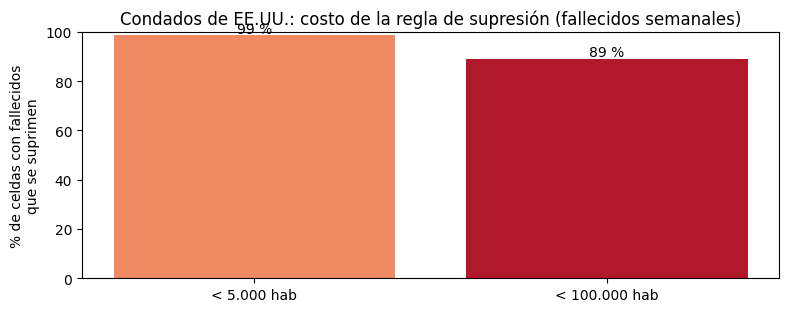

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.2))
d = perdida[perdida['medida'] == 'fallecidos']
ax.bar(['< 5.000 hab', '< 100.000 hab'], d['% de sus celdas con valor > 0'], color=['#ef8a62', '#b2182b'])
for i, v in enumerate(d['% de sus celdas con valor > 0']):
    ax.text(i, v + 1, f'{v:.0f} %', ha='center')
ax.set_ylabel('% de celdas con fallecidos\nque se suprimen')
ax.set_title('Condados de EE.UU.: costo de la regla de supresión (fallecidos semanales)')
ax.set_ylim(0, 100)
plt.show()

**Resultado:** con el umbral de **5.000 habitantes** se afectan **316 condados**: casi todas sus semanas con fallecidos (99 %) se publican como "1–4", pero eso oculta solo el **0,34 %** de los fallecidos del país. Con el umbral de **100.000** se afectan **2.621 condados** y se oculta el **16 %** de los fallecidos: la protección sale demasiado cara.

**Decisión:** el tablero usa 100.000 porque solo muestra países y regiones de Chile, donde la regla casi no aplica. Si se publican condados, se usa el umbral de 5.000 con supresión complementaria, o se agrega a nivel de estado.

## 5 · Advertencias de interpretación para el Comité
1. **La letalidad aparente depende del testeo.** Fallecidos ÷ casos detectados: si un país testea poco, solo detecta los casos graves y su letalidad parece alta (Perú 2020: 9,4 % en P3). No es la probabilidad real de morir al contagiarse.
2. **Comparar países exige cautela.** Cada país definió distinto qué es un "fallecido por COVID-19" (confirmado o probable), testeó distinto y publicó con rezagos distintos. Un ranking de países mezcla epidemia y sistema de registro (P4: índice de calidad).
3. **Los totales cambian por correcciones.** Acumulados que bajan, cargas de rezagos (Chile, 17-jun-2020) y el archivo defectuoso del 23-may-2022: un número de un solo día puede estar mal; se usan medias móviles de 7 días.
4. **Desde 2022 muchos países informan una vez por semana**: un "0" diario no significa que no hubo casos.
5. **Correlación no es causalidad** (P3, P7): vacunación, variante, testeo y edad de la población cambian juntos en el tiempo y entre países.